# Colab evaluation: A Century of Portraits (single-task vs MTL)

Use this notebook **only to evaluate saved checkpoints**. It does not train.

## What you must have on Google Drive (or uploaded to Colab)

1. The dataset archive, e.g. `faces_aligned_small_mirrored_co_aligned_cropped_cleaned.tar.gz`
2. `portrait_mtl.py` from this project (model + dataset code)
3. Both checkpoints:
   - `single/best.pt` (year-only model)
   - `multi_0p05/best.pt` (year + gender model)

## Recommended Drive layout

```
MyDrive/ml_midterm/
  faces_aligned_small_mirrored_co_aligned_cropped_cleaned.tar.gz
  portrait_mtl.py
  runs/single/best.pt
  runs/multi_0p05/best.pt
```

## How to run

1. Runtime → Change runtime type → **T4 GPU** (or any GPU).
2. Edit the **paths cell** so it matches your Drive folder names.
3. Run all cells **top to bottom once**.
4. Do not re-run the evaluation cell after you already have test numbers unless you set `FORCE_REEVAL = True`.

## 1. Enable GPU and confirm CUDA

**What to do:** Runtime → Change runtime type → GPU, then run this cell.

You should see `True` and a GPU name such as `Tesla T4`. If you see `False`, evaluation still works on CPU but will be slower.

In [2]:
# Instruction: run after selecting a GPU runtime.
%matplotlib inline
import matplotlib
matplotlib.rcParams["figure.facecolor"] = "white"
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. Evaluation will work, but expect several minutes.")

CUDA available: False
Running on CPU. Evaluation will work, but expect several minutes.


## 2. Install Python packages

**What to do:** Run once per Colab session. Colab already has PyTorch; this adds plotting helpers if they are missing.

In [3]:
# Instruction: on Colab, install extras. On a local machine, skip if packages already exist.
try:
    import google.colab  # noqa: F401
    %pip install -q pandas matplotlib seaborn pillow scikit-learn
except ImportError:
    print("Not Colab; using the local Python environment.")

Not Colab; using the local Python environment.


## 3. Mount Google Drive

**What to do:** Run this cell and click the permission prompt.

If your files are already uploaded under `/content` (not Drive), you can skip this cell.

In [4]:
# Instruction: authorize Drive only in Colab. Local runs skip this.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not Colab; Drive mount skipped.")

Not Colab; Drive mount skipped.


## 4. Set your paths (edit this cell)

**What to do:** Change `DRIVE_ROOT` and the checkpoint filenames so they match **your** Drive.

Keep data on Colab local disk (`/content/data`), not on Drive, or image loading will be very slow.

In [5]:
# Instruction: EDIT only if your files live somewhere else.
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ARCHIVE_NAME = "faces_aligned_small_mirrored_co_aligned_cropped_cleaned.tar.gz"
FORCE_REEVAL = True  # set False after a successful run if you want to lock test eval

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive/ml_midterm")
    LOCAL_DATA = Path("/content/data")
    LOCAL_CODE = Path("/content")
    LOCAL_OUT = Path("/content/eval_out")
    SINGLE_CKPT_SRC = DRIVE_ROOT / "runs" / "single" / "best.pt"
    MULTI_CKPT_SRC = DRIVE_ROOT / "runs" / "multi_0p05" / "best.pt"
    CODE_SRC = DRIVE_ROOT / "portrait_mtl.py"
else:
    DRIVE_ROOT = Path("/Users/ahmadhamdy/Desktop/Midterm_ML")
    LOCAL_DATA = DRIVE_ROOT / "data"
    LOCAL_CODE = DRIVE_ROOT
    LOCAL_OUT = DRIVE_ROOT / "eval_out"
    SINGLE_CKPT_SRC = DRIVE_ROOT / "runs" / "single" / "best.pt"
    MULTI_CKPT_SRC = DRIVE_ROOT / "runs" / "multi_0p05" / "best.pt"
    CODE_SRC = DRIVE_ROOT / "portrait_mtl.py"

print("Colab:", IN_COLAB)
print("Data dir exists:", LOCAL_DATA.exists())
print("portrait_mtl.py exists:", CODE_SRC.exists())
print("Single checkpoint exists:", SINGLE_CKPT_SRC.exists())
print("Multi checkpoint exists:", MULTI_CKPT_SRC.exists())

Colab: False
Data dir exists: True
portrait_mtl.py exists: True
Single checkpoint exists: True
Multi checkpoint exists: True


## 5. Copy code/checkpoints and unpack the dataset locally

**What to do:** Run once per session. Copying + unpacking usually takes 1–3 minutes.

This cell unpacks the official `F/`, `M/`, and split `.txt` files. You do **not** need `portraits.sqlite3` for Colab.

In [6]:
# Instruction: Colab copies/unpacks from Drive. Locally, reuse data/ and runs/.
import shutil
from pathlib import Path

LOCAL_DATA.mkdir(parents=True, exist_ok=True)
LOCAL_OUT.mkdir(parents=True, exist_ok=True)
shutil.copy(SINGLE_CKPT_SRC, LOCAL_OUT / "single_best.pt")
shutil.copy(MULTI_CKPT_SRC, LOCAL_OUT / "multi_best.pt")
if CODE_SRC.resolve() != (LOCAL_CODE / "portrait_mtl.py").resolve():
    shutil.copy(CODE_SRC, LOCAL_CODE / "portrait_mtl.py")

split_ready = all(
    (LOCAL_DATA / name).exists() or any(LOCAL_DATA.rglob(name))
    for name in ("test_F.txt", "test_M.txt", "train_F.txt", "train_M.txt")
)
sqlite_ready = any(LOCAL_DATA.rglob("portraits.sqlite3"))

if IN_COLAB and not split_ready:
    archive_local = Path("/content") / ARCHIVE_NAME
    if not archive_local.exists():
        print("Copying archive from Drive to local disk...")
        shutil.copy(DRIVE_ROOT / ARCHIVE_NAME, archive_local)
    print("Unpacking archive...")
    get_ipython().system(f'tar -xzf "{archive_local}" -C "{LOCAL_DATA}"')
elif split_ready:
    print("Found split files. SQLite image DB:", sqlite_ready)
else:
    raise FileNotFoundError(
        f"No test/train split files under {LOCAL_DATA}. Download or unpack the dataset first."
    )

print("Checkpoints in", LOCAL_OUT)
print("Data listing:", sorted(p.name for p in LOCAL_DATA.iterdir()))

Found split files. SQLite image DB: True
Checkpoints in /Users/ahmadhamdy/Desktop/Midterm_ML/eval_out
Data listing: ['faces_aligned_small_mirrored_co_aligned_cropped_cleaned']


## 6. Seed, imports, and locate the dataset root

**What to do:** Run as-is. This cell finds the folder that contains `train_F.txt`, `train_M.txt`, `test_F.txt`, and `test_M.txt`.

In [7]:
# Instruction: no edits needed unless unpacking put files somewhere unexpected.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
from IPython.display import display

sys.path.insert(0, str(LOCAL_CODE))
from portrait_mtl import (
    SEED,
    find_dataset_root,
    load_model_checkpoint,
    make_loaders,
    predict_all,
    select_device,
    set_seed,
)

set_seed(SEED)
DATA_ROOT = find_dataset_root(LOCAL_DATA)
DEVICE = select_device("auto")
print("Seed:", SEED)
print("Dataset root:", DATA_ROOT)
print("Device:", DEVICE)
print("Split files:", sorted(p.name for p in DATA_ROOT.glob("*.txt")))

Seed: 1
Dataset root: /Users/ahmadhamdy/Desktop/Midterm_ML/data/faces_aligned_small_mirrored_co_aligned_cropped_cleaned
Device: cpu
Split files: ['test_F.txt', 'test_M.txt', 'train_F.txt', 'train_M.txt']


## 7. Build the official test loader

**What to do:** Run as-is.

This uses the provided train/test lists. Validation is created from train only (needed by the shared loader) but **is not used for model selection here**. Test images are touched only in the next evaluation cell.

In [8]:
# Instruction: run once. Lower BATCH_SIZE to 64 if Colab runs out of GPU memory.
BATCH_SIZE = 64 if not IN_COLAB else 128
WORKERS = 0 if not IN_COLAB else 2  # sqlite + forked workers is unreliable locally

loaders, audits = make_loaders(
    DATA_ROOT,
    batch_size=BATCH_SIZE,
    workers=WORKERS,
    image_size=224,
    include_test=True,
)
print("Train listed (before val split):", audits["train"]["valid"])
print("Test listed:", audits["test"]["valid"], "excluded:", audits["test"]["excluded"])
print("Test batches:", len(loaders["test"]))

Train listed (before val split): 29152
Test listed: 7408 excluded: 0
Test batches: 7408


## 8. Load both `best.pt` checkpoints

**What to do:** Run as-is.

Each checkpoint stores architecture (`task`: `single` or `multi`) plus weights. Models are rebuilt with `pretrained=False` and then filled from the file.

In [9]:
# Instruction: run after checkpoints were copied to /content/eval_out.
single_model, single_cfg = load_model_checkpoint(LOCAL_OUT / "single_best.pt", DEVICE)
multi_model, multi_cfg = load_model_checkpoint(LOCAL_OUT / "multi_best.pt", DEVICE)
single_model.eval()
multi_model.eval()
print("Single-task config task:", single_cfg.get("task"))
print("Multi-task config task:", multi_cfg.get("task"))
print("Loaded both checkpoints onto", DEVICE)

Single-task config task: single
Multi-task config task: multi
Loaded both checkpoints onto cpu


## 9. Final test evaluation (run once)

**What to do:** Run this cell **once**. It scores the full test split for both models.

Metrics are computed on all test predictions at once (not averaged per batch).
Year predictions are converted back from `[0, 1]` to calendar years before MAE.

If you already ran it and need to repeat, set `FORCE_REEVAL = True` in the paths cell and re-run from there.

In [10]:
# Instruction: run once per Colab session unless FORCE_REEVAL is True.
import json

marker = LOCAL_OUT / "FINAL_TEST_EVALUATION_COMPLETE"
if marker.exists() and not FORCE_REEVAL:
    raise RuntimeError(
        f"Test evaluation already finished ({marker}). "
        "Set FORCE_REEVAL = True in the paths cell if you intentionally want to rerun."
    )

use_amp = DEVICE.type == "cuda"
single_pred = predict_all(single_model, loaders["test"], DEVICE, single_cfg["task"], use_amp)
multi_pred = predict_all(multi_model, loaders["test"], DEVICE, multi_cfg["task"], use_amp)

final_metrics = {
    "protocol": "Colab evaluation of saved checkpoints on the official test split.",
    "dataset_root": str(DATA_ROOT),
    "single": {"year_mae": single_pred["year_mae"]},
    "multi": {
        key: multi_pred[key]
        for key in ("year_mae", "gender_accuracy", "gender_f1")
        if key in multi_pred
    },
}
(LOCAL_OUT / "final_metrics.json").write_text(json.dumps(final_metrics, indent=2) + "\n")

predictions = pd.DataFrame(
    {
        "path": single_pred["path"],
        "target_year": single_pred["target_year"],
        "single_predicted_year": single_pred["predicted_year"],
        "multi_predicted_year": multi_pred["predicted_year"],
        "target_gender": multi_pred.get("target_gender"),
        "multi_predicted_gender": multi_pred.get("predicted_gender"),
    }
)
predictions.to_csv(LOCAL_OUT / "test_predictions.csv", index=False)
marker.write_text("done\n")
print(json.dumps(final_metrics, indent=2))

{
  "protocol": "Colab evaluation of saved checkpoints on the official test split.",
  "dataset_root": "/Users/ahmadhamdy/Desktop/Midterm_ML/data/faces_aligned_small_mirrored_co_aligned_cropped_cleaned",
  "single": {
    "year_mae": 3.4438871544329186
  },
  "multi": {
    "year_mae": 3.481974080623355,
    "gender_accuracy": 0.9617980561555075,
    "gender_f1": 0.9569057408253389
  }
}


## 10. Print the required test-set table

**What to do:** Run after evaluation finishes. This is the labeled final-results cell for the report: year MAE for both models, plus gender accuracy and F1 for MTL.

In [11]:
# Instruction: this is the final numbered result table. Copy these numbers into the report.
result_table = pd.DataFrame(
    [
        {
            "model": "Single-task",
            "test_year_MAE": final_metrics["single"]["year_mae"],
            "gender_accuracy": np.nan,
            "gender_F1": np.nan,
        },
        {
            "model": "Multi-task",
            "test_year_MAE": final_metrics["multi"]["year_mae"],
            "gender_accuracy": final_metrics["multi"].get("gender_accuracy", np.nan),
            "gender_F1": final_metrics["multi"].get("gender_f1", np.nan),
        },
    ]
).set_index("model")
print("Better year MAE:", result_table["test_year_MAE"].min())
display(result_table.round(4))

Better year MAE: 3.4438871544329186


,test_year_MAE,gender_accuracy,gender_F1
model,,,
Single-task,3.4439,NaN,NaN
Multi-task,3.4820,0.9618,0.9569


## 11. Plot year MAE, scatter, and gender confusion

**What to do:** Run to generate figures. Files are saved under `/content/eval_out/`.

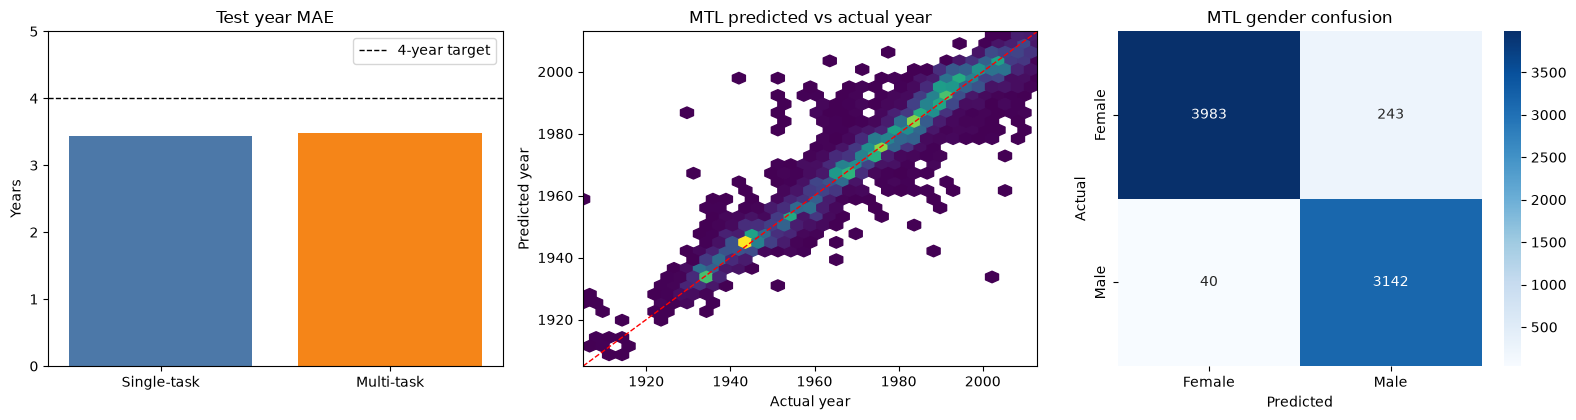

In [12]:
# Instruction: run after the results table. Figures are written next to the metrics JSON.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

axes[0].bar(result_table.index, result_table["test_year_MAE"], color=["#4c78a8", "#f58518"])
axes[0].axhline(4.0, color="black", linestyle="--", linewidth=1, label="4-year target")
axes[0].set(title="Test year MAE", ylabel="Years", ylim=(0, max(5, result_table["test_year_MAE"].max() + 0.5)))
axes[0].legend()

axes[1].hexbin(
    predictions["target_year"],
    predictions["multi_predicted_year"],
    gridsize=35,
    mincnt=1,
    cmap="viridis",
)
axes[1].plot([1905, 2013], [1905, 2013], "r--", linewidth=1)
axes[1].set(
    title="MTL predicted vs actual year",
    xlabel="Actual year",
    ylabel="Predicted year",
    xlim=(1905, 2013),
    ylim=(1905, 2013),
)

if predictions["target_gender"].notna().any():
    confusion = pd.crosstab(
        predictions["target_gender"].map({0: "Female", 1: "Male"}),
        predictions["multi_predicted_gender"].map({0: "Female", 1: "Male"}),
    )
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", ax=axes[2])
    axes[2].set(title="MTL gender confusion", xlabel="Predicted", ylabel="Actual")

fig.tight_layout()
fig.savefig(LOCAL_OUT / "eval_plots.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 12. Show sample portraits from unpacked `F/` and `M/` folders

**What to do:** Run as-is. This reads image **files**, not SQLite.

If a sample path is missing, the title will say so instead of crashing.

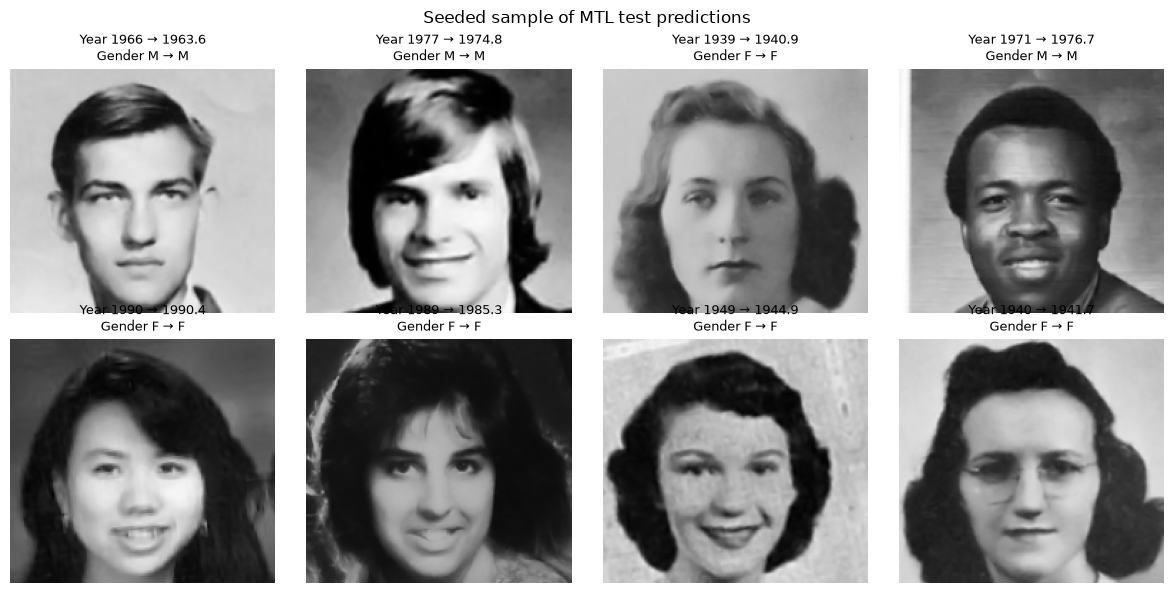

In [13]:
# Instruction: loads F/M image files, or blobs from portraits.sqlite3.
import io
import sqlite3

examples = predictions.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
sqlite_path = DATA_ROOT / "portraits.sqlite3"
connection = sqlite3.connect(sqlite_path) if sqlite_path.exists() else None

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    relative = "/".join(Path(str(row["path"])).parts[-2:])
    image_path = DATA_ROOT / relative
    image = None
    if image_path.is_file():
        image = Image.open(image_path).convert("RGB")
    elif connection is not None:
        hit = connection.execute("SELECT data FROM images WHERE path = ?", (relative,)).fetchone()
        if hit:
            image = Image.open(io.BytesIO(hit[0])).convert("RGB")
    if image is None:
        ax.set_title(f"Missing\n{relative}", fontsize=8)
        ax.axis("off")
        continue
    ax.imshow(image)
    actual_g = "M" if row["target_gender"] else "F"
    pred_g = "M" if row["multi_predicted_gender"] else "F"
    ax.set_title(
        f"Year {row['target_year']:.0f} → {row['multi_predicted_year']:.1f}\n"
        f"Gender {actual_g} → {pred_g}",
        fontsize=9,
    )
    ax.axis("off")

if connection is not None:
    connection.close()
fig.suptitle("Seeded sample of MTL test predictions")
fig.tight_layout()
fig.savefig(LOCAL_OUT / "sample_predictions.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 13. Optional: copy results back to Drive

**What to do:** Run if you want `final_metrics.json`, the CSV, and plots to survive after the Colab VM is deleted.

In [14]:
if not IN_COLAB:
    print("Local run: results already in", LOCAL_OUT)
else:
    dest = DRIVE_ROOT / "colab_eval_out"
    dest.mkdir(parents=True, exist_ok=True)
    for name in (
        "final_metrics.json",
        "test_predictions.csv",
        "eval_plots.png",
        "sample_predictions.png",
    ):
        src = LOCAL_OUT / name
        if src.exists():
            shutil.copy(src, dest / name)
            print("Saved", dest / name)
        else:
            print("Missing", src)

Local run: results already in /Users/ahmadhamdy/Desktop/Midterm_ML/eval_out
